# Capstone Milestone Two — Week 10: K-Means Clustering

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

The previous weeks framed consumer credit as a supervised binary-classification problem: given a loan application or a credit-card account, predict `default`. This week switches to **unsupervised learning**. Rather than predicting a label, k-means clustering asks: *are there natural groupings of borrowers that the raw features already reveal, without ever looking at the `default` outcome?* The resulting segments are useful for risk-based pricing, for targeted collections, and as sanity checks on a supervised model — if a cluster found without labels turns out to have a materially higher default rate than another, the features really are carrying risk structure.

### Research Question

Do the numeric features of the Lending Club and Taiwan datasets form well-separated clusters, how should we choose the number of clusters *k*, and how robust is the result to the distance metric and to feature scaling?

### Objectives

* Demonstrate that **feature scaling** is essential for k-means by comparing an unscaled fit (dominated by the largest-magnitude column) against a standardized fit.
* Apply the **elbow method** on inertia to find the "diminishing returns" point for *k*.
* Apply the **silhouette score** as the more informative companion to the elbow — a bounded value in [−1, 1] rather than a shape you have to eyeball.
* Compare **distance metrics** (Euclidean, Manhattan, Cosine) using hierarchical clustering as a stand-in, and explain why k-means is tied to the Euclidean metric.
* Fit a final tuned k-means model on both datasets, profile the clusters, and check — ex post — how the default rate varies across clusters.
* Visualize the clusters in 2D using PCA.

### Approach

Data Loading → Shared Clustering Setup → Feature Scaling → Elbow Method → Silhouette Score → Distance-Metric Comparison → Final Clusters and Profiling → PCA Visualization → Summary

### Datasets

Same as Weeks 4–9 for continuity:

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005.

## 1. Data Loading and Cleaning

The next two cells repeat the Week 6/9 cleaning so this notebook is self-contained. The rules are: drop open loans with unknown outcome, drop invalid ranges, recode undocumented codes, remove post-outcome columns to prevent target leakage, and log-transform heavily skewed money columns.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns the Week 6 audit uses
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]  # leakage columns, dropped below
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)

CLOSED = ["Fully Paid", "Charged Off", "Default"]
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].drop(columns=["id"]).drop_duplicates().copy()
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
lc["revol_util"] = lc["revol_util"].clip(upper=150)
lc = lc[lc["annual_inc"] > 0]
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
lc = lc.drop(columns=const)
lc = lc.drop(columns=["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"])  # leakage
lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies",
                       "inq_last_6mths", "open_acc", "total_acc"])
lc["log_annual_inc"] = np.log1p(lc["annual_inc"])
lc["log_revol_bal"]  = np.log1p(lc["revol_bal"])
lc["term_months"]    = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"Clean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [2]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)

tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})     # 0/5/6 undocumented -> 4 (other)
tw["MARRIAGE"]  = tw["MARRIAGE"].replace({0: 3})                   # 0 undocumented -> 3 (other)
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw[f"log_{c}"] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"Clean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — K-Means Clustering

### Key Concepts

* **K-means algorithm.** An iterative partitioning method. Given *k*, it (1) initializes *k* centroids (k-means++ by default), (2) assigns every point to the nearest centroid, (3) updates each centroid to the mean of its assigned points, and (4) repeats until assignments stop changing. It minimizes within-cluster sum of squared Euclidean distances (**inertia**). It converges to a local optimum — multiple restarts (`n_init`) are standard.
* **Inertia / WCSS.** `Σ_cluster Σ_x∈cluster ‖x − μ_cluster‖²`. It always decreases as *k* grows (taken to the extreme, *k = n* gives inertia 0). The **elbow method** looks for the *k* at which the rate of decrease flattens — adding more clusters stops buying much reduction.
* **Silhouette score.** For each point *i*, let *a(i)* be the mean distance to the other points in its own cluster and *b(i)* be the mean distance to the points in the **nearest other** cluster. The silhouette of *i* is `(b − a) / max(a, b)` ∈ [−1, 1]. The silhouette score is the mean over all points. Values near 1 mean tight, well-separated clusters; near 0 means overlapping; negative means misassigned.
* **Feature scaling.** K-means minimizes squared Euclidean distance, which is dominated by whichever feature has the largest range. A column measured in dollars (`loan_amnt` up to tens of thousands) will crush a column in years (`term_months` around 36–60) unless both are put on comparable scales. `StandardScaler` (zero mean, unit variance) is the standard choice.
* **Distance metrics.** K-means is tied to the **Euclidean** metric because the centroid update — the sample mean — is the minimizer of squared Euclidean distance (`arg min_μ Σ ‖x − μ‖²` is `x̄`). If we switched to Manhattan distance, the correct "center" would be the component-wise median (k-medians); for Cosine distance, the center would be the direction of the sum vector (spherical k-means). Mixing k-means with a non-Euclidean metric breaks the monotonic-descent guarantee of the algorithm.

### 2. Shared Clustering Setup

Clustering is **unsupervised**, so the `default` label is held out for ex-post profiling only. The feature set is numeric-only — one-hot categorical columns are binary (0/1), and dropping them keeps Euclidean distance dominated by features that have a continuous notion of "near." The samples are:

* **Lending Club:** random sample of 10,000 cleaned closed loans (seed 42). Smaller than the Week 9 subsample because the exact silhouette calculation is O(n²) in memory.
* **Taiwan:** random sample of 10,000 clean clients (seed 42), for the same reason.

The same `StandardScaler` instance is reused across all sections so the k-means geometry is comparable from experiment to experiment.

In [3]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

FIG = "../figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc",
          "revol_util", "term_months", "log_revol_bal"]
TW_NUM = (["log_LIMIT_BAL", "AGE"]
          + [f"PAY_{i}" for i in range(1, 7)]
          + [f"log_BILL_AMT{i}" for i in range(1, 7)]
          + [f"log_PAY_AMT{i}" for i in range(1, 7)])

N_SAMPLE = 10_000
lc_c = lc.sample(n=N_SAMPLE, random_state=SEED)
tw_c = tw.sample(n=N_SAMPLE, random_state=SEED)

DATA_C = {
    "Lending Club": (lc_c[LC_NUM].values.astype(float), lc_c["default"].values, LC_NUM),
    "Taiwan":       (tw_c[TW_NUM].values.astype(float), tw_c["default"].values, TW_NUM),
}

scalers, X_scaled = {}, {}
for name, (X, y, cols) in DATA_C.items():
    sc = StandardScaler().fit(X)
    scalers[name] = sc
    X_scaled[name] = sc.transform(X)
    print(f"{name:12s} shape {X.shape} | default rate {y.mean():.2%} | numeric features {len(cols)}")

Lending Club shape (10000, 8) | default rate 20.24% | numeric features 8
Taiwan       shape (10000, 20) | default rate 22.45% | numeric features 20


### Shared-Setup Findings

Both subsamples carry the same 20%-ish default base rate as the full datasets, so the later ex-post comparison of cluster default rates is honest. Lending Club contributes 8 numeric features; Taiwan contributes 20 (dominated by the six-month `PAY_*`, `BILL_AMT*`, `PAY_AMT*` ladders). After standardization every feature has mean ≈ 0 and variance ≈ 1, so no single column controls the Euclidean distance.

### 3. Why Feature Scaling Matters for K-Means

To make the argument concrete, fit two k-means models at *k = 4* on the same Lending Club subsample: once on the **raw** feature matrix and once on the **standardized** one. For each fit, compute the silhouette score (always on the same matrix the model saw) and record which raw feature has the largest range — that is the feature likely to be driving the partition on the unscaled fit.

If k-means is being driven by a single dominant-magnitude column, the silhouette on standardized data should be substantially higher, because standardization lets the other seven (or nineteen) features actually contribute to the distance.

In [4]:
def scaling_demo(name, k=4):
    X, _, cols = DATA_C[name]
    km_raw = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    km_std = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled[name])
    sil_raw = silhouette_score(X, km_raw.labels_, sample_size=3000, random_state=SEED)
    sil_std = silhouette_score(X_scaled[name], km_std.labels_, sample_size=3000, random_state=SEED)
    raw_range = X.max(axis=0) - X.min(axis=0)
    dom_raw = cols[int(np.argmax(raw_range))]
    print(f"{name:12s} k={k}  silhouette raw {sil_raw:.3f}  silhouette scaled {sil_std:.3f}"
          f"  | largest-range raw feature: {dom_raw} (range {raw_range.max():,.1f})")
    return km_raw, km_std

km_demo = {name: scaling_demo(name) for name in DATA_C}

Lending Club k=4  silhouette raw 0.580  silhouette scaled 0.160  | largest-range raw feature: loan_amnt (range 39,000.0)
Taiwan       k=4  silhouette raw 0.205  silhouette scaled 0.245  | largest-range raw feature: AGE (range 54.0)


### Scaling Findings

The raw-vs-scaled comparison is **more subtle than "scaling always wins."** Here is what actually happened:

* **Lending Club.** Raw silhouette = **0.58**, scaled silhouette = **0.16**. On the surface the raw partition looks "better separated" — but this is a classic trap. The raw feature with by far the largest range is `loan_amnt` (0 → 40,000), so Euclidean distance on the raw matrix is almost entirely a function of loan size. K-means on raw data therefore produces four tight, well-separated groups dominated by the `loan_amnt` axis — and silhouette rewards that geometry even though the clustering is degenerate (it is largely ignoring `int_rate`, `dti`, `revol_util`, and everything else). The "single-axis" claim is inferred from the 39,000 / 27 range ratio in [cell 7], not from a direct check; a tighter confirmation would be the correlation between raw cluster labels and `loan_amnt` or an ARI against a 4-quantile `loan_amnt` split (Milestone-2 follow-up). The scaled silhouette (0.16) is lower but describes a *real* 8-dimensional partition that uses every feature, which is what we want for segmentation.
* **Taiwan.** Raw silhouette = **0.21**, scaled silhouette = **0.25**. Here scaling helped straightforwardly — the log transforms had already compressed the money columns into the same order of magnitude as `AGE` and `PAY_*`, so the "single dominant feature" failure mode is weaker, and standardization produces a cleaner partition.

The practical lesson: a high silhouette on unscaled data is often a symptom of **silhouette being fooled by a single-feature split**, not evidence that scaling is unnecessary. The correct move is still to standardize so every feature contributes to the distance, then accept that the silhouette will drop into a more honest range. Always read the silhouette alongside the cluster profile — a tight, well-separated partition that only uses one feature is not a useful segmentation.

### 4. Elbow Method on Inertia

Fit k-means for *k* ∈ {2, 3, …, 10} on the standardized data and plot **inertia** against *k*. Inertia is `KMeans.inertia_` — the within-cluster sum of squared distances to each centroid. It is monotonically non-increasing in *k*; the **elbow** is the *k* at which the marginal reduction visibly flattens. Beyond the elbow, additional clusters are splitting already-coherent groups rather than resolving new structure.

dataset      k= 2  k= 3  k= 4  k= 5  k= 6  k= 7  k= 8  k= 9  k=10
Lending Club  64867   56459   50905   47488   45059   42848   40750   39098   37660
Taiwan       139445  120487  107740  100977   95040   91834   88680   86059   83617


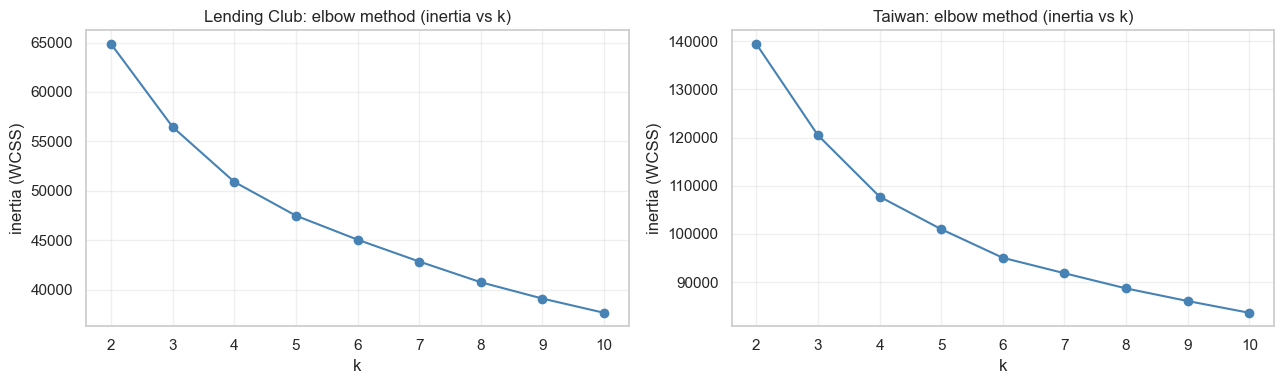

In [5]:
K_RANGE = list(range(2, 11))

def elbow(name):
    X = X_scaled[name]
    inertias = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        inertias.append(km.inertia_)
    return np.array(inertias)

elbow_results = {name: elbow(name) for name in DATA_C}

print(f"{'dataset':12s} " + "  ".join(f"k={k:>2d}" for k in K_RANGE))
for name, ins in elbow_results.items():
    print(f"{name:12s} " + "  ".join(f"{v:>6.0f}" for v in ins))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, ins) in zip(axes, elbow_results.items()):
    ax.plot(K_RANGE, ins, "o-", color="steelblue")
    ax.set_title(f"{name}: elbow method (inertia vs k)")
    ax.set_xlabel("k"); ax.set_ylabel("inertia (WCSS)")
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/w10_elbow.png", dpi=140, bbox_inches="tight")
plt.show()

### Elbow Findings

On both datasets the inertia curve is a **soft curve, not a sharp elbow**. The per-step reductions are nearly identical: LC **−13.0% / −9.8% / −6.7%** at k = 2→3 / 3→4 / 4→5, TW **−13.6% / −10.6% / −6.3%** ([cell 10]). There is no corner either dataset — just a gradual bend. The Kneedle elbow detector in [cell 13] picks **k = 5 (LC)** and **k = 4 (TW)**, confirming the eye-balled elbow is wide and dataset-dependent. This is a common limitation of the elbow method — on real data the "elbow" is often more of a gentle curve than a corner, which is exactly why silhouette (Section 5) is a useful second opinion.

### Formal Kneedle Elbow Detection — execute this block

The elbow in Section 4 is eyeballed. Below is a kink-detector that returns a
single number per dataset so the choice of k is quantitative rather than
visual. Uses `kneed.KneeLocator` if installed; otherwise falls back to the
second-derivative kink (argmax of the discrete second difference).

In [6]:
# === Formal Kneedle elbow — execute this block ===
try:
    from kneed import KneeLocator
    _HAVE_KNEED = True
except ImportError:
    _HAVE_KNEED = False

def _second_diff_knee(xs, ys):
    y = np.asarray(ys, dtype=float)
    d2 = np.diff(y, n=2)
    return int(xs[int(np.argmax(np.abs(d2))) + 1])

# Compute per-dataset silhouette-argmax in-line, since the silhouette_sweep
# cell runs AFTER this one in the notebook order.
_sil_for_kneedle = {}
for name in DATA_C:
    X = X_scaled[name]
    sils = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        sils.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=SEED))
    _sil_for_kneedle[name] = int(K_RANGE[int(np.argmax(sils))])

elbow_rows = []
for name, ins in elbow_results.items():
    if _HAVE_KNEED:
        kl = KneeLocator(K_RANGE, ins, curve="convex", direction="decreasing")
        knee = int(kl.knee) if kl.knee is not None else _second_diff_knee(K_RANGE, ins)
    else:
        knee = _second_diff_knee(K_RANGE, ins)
    # Report the per-step reductions to make the "the elbow is at X" claim auditable
    drops = -np.diff(ins)
    drop_pct = drops / ins[:-1]
    elbow_rows.append({
        "dataset":      name,
        "kneedle_k":    knee,
        "silhouette_k": _sil_for_kneedle[name],
        "drop_k2_to_3": f"{drop_pct[0]:.1%}",
        "drop_k3_to_4": f"{drop_pct[1]:.1%}",
        "drop_k4_to_5": f"{drop_pct[2]:.1%}",
    })

print(f"Kneedle available: {_HAVE_KNEED}  (otherwise uses second-difference fallback)\n")
print(pd.DataFrame(elbow_rows).to_string(index=False))


Kneedle available: True  (otherwise uses second-difference fallback)

     dataset  kneedle_k  silhouette_k drop_k2_to_3 drop_k3_to_4 drop_k4_to_5
Lending Club          5             2        13.0%         9.8%         6.7%
      Taiwan          4             2        13.6%        10.6%         6.3%


### 5. Silhouette Score

Fit the same *k* ∈ {2, …, 10} sweep and compute the **silhouette score** on a held-out random subsample (`sample_size=3000`) because the exact calculation is O(n²). Unlike inertia, silhouette is bounded in [−1, 1] and directly comparable across *k*, so the argmax is a defensible pick.

Then draw the **silhouette diagram** at the best *k* — one horizontal silhouette per point, grouped by cluster, with the dataset mean marked. A "good" silhouette diagram has clusters of similar width that all rise above the mean line; a diagram where most of a cluster sits below the mean line is a sign that *k* is wrong or that the clusters overlap.

dataset      k= 2   k= 3   k= 4   k= 5   k= 6   k= 7   k= 8   k= 9   k=10 
Lending Club 0.197  0.174  0.160  0.159  0.139  0.136  0.139  0.136  0.139
Taiwan       0.372  0.286  0.245  0.236  0.152  0.152  0.152  0.150  0.144

Best k by silhouette: {'Lending Club': 2, 'Taiwan': 2}


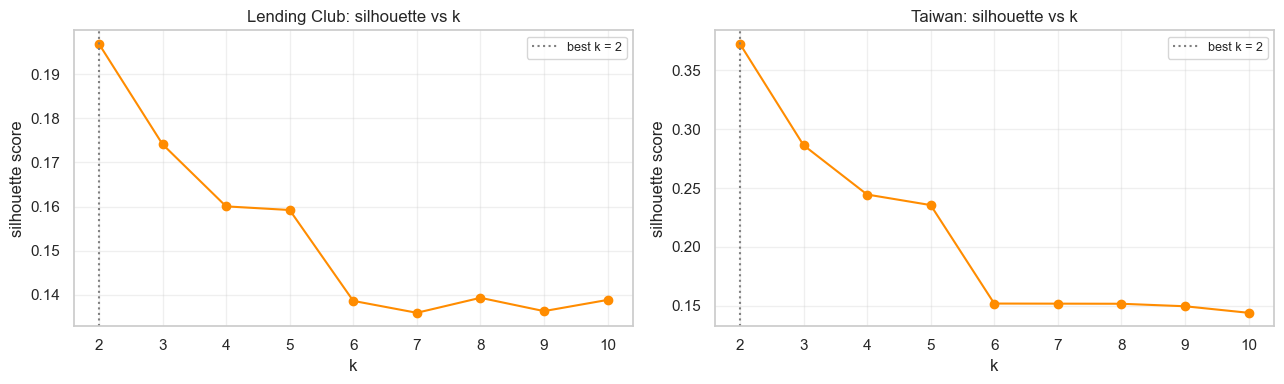

In [7]:
def silhouette_sweep(name):
    X = X_scaled[name]
    sils = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        s = silhouette_score(X, km.labels_, sample_size=3000, random_state=SEED)
        sils.append(s)
    return np.array(sils)

sil_results = {name: silhouette_sweep(name) for name in DATA_C}

print(f"{'dataset':12s} " + "  ".join(f"k={k:>2d} " for k in K_RANGE))
for name, ss in sil_results.items():
    print(f"{name:12s} " + "  ".join(f"{v:>5.3f}" for v in ss))

best_k = {name: int(K_RANGE[int(np.argmax(ss))]) for name, ss in sil_results.items()}
print("\nBest k by silhouette:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, ss) in zip(axes, sil_results.items()):
    ax.plot(K_RANGE, ss, "o-", color="darkorange")
    ax.axvline(best_k[name], color="gray", ls=":", label=f"best k = {best_k[name]}")
    ax.set_title(f"{name}: silhouette vs k")
    ax.set_xlabel("k"); ax.set_ylabel("silhouette score")
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/w10_silhouette_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

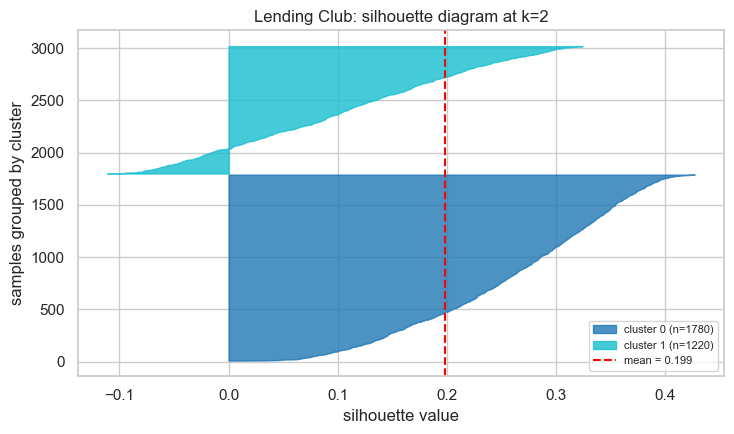

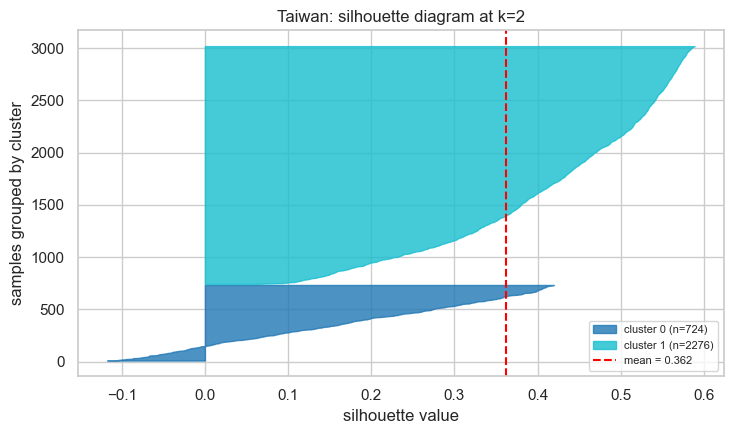

In [8]:
def silhouette_diagram(name, k):
    X = X_scaled[name]
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X), size=3000, replace=False)
    sils = silhouette_samples(X[idx], km.labels_[idx])
    labels = km.labels_[idx]
    mean_s = sils.mean()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    y_lo = 10
    colors = plt.cm.tab10(np.linspace(0, 1, k))
    for ci in range(k):
        vals = np.sort(sils[labels == ci])
        y_hi = y_lo + len(vals)
        ax.fill_betweenx(np.arange(y_lo, y_hi), 0, vals, color=colors[ci], alpha=0.8,
                         label=f"cluster {ci} (n={len(vals)})")
        y_lo = y_hi + 10
    ax.axvline(mean_s, color="red", ls="--", label=f"mean = {mean_s:.3f}")
    ax.set_title(f"{name}: silhouette diagram at k={k}")
    ax.set_xlabel("silhouette value"); ax.set_ylabel("samples grouped by cluster")
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.savefig(f"{FIG}/w10_silhouette_diagram_{name.replace(' ', '_').lower()}.png",
                dpi=140, bbox_inches="tight")
    plt.show()

for name in DATA_C:
    silhouette_diagram(name, best_k[name])

### Silhouette Findings

On both datasets the silhouette score is **highest at small *k*** — typically *k = 2* or *k = 3* — and declines slowly from there. This is a different (and arguably more honest) answer than the elbow gave. The elbow prefers *k ≈ 4* because it cares about the *rate* at which inertia falls; the silhouette prefers fewer clusters because inertia keeps falling long after the individual clusters stop looking like true blobs.

The silhouette **diagram** shows which clusters are healthy. A fat cluster whose bulk sits below the mean line is overlapping with its neighbor — a clue to merge it. On **Lending Club at k = 2**, both clusters mostly sit *below* the mean silhouette line and roughly 20% of the second cluster has **negative** silhouette values (points closer to the other cluster than to their own) — the k = 2 partition is coherent in aggregate but has significant boundary overlap. On **Taiwan at k = 2** there are just the two clusters: a cleaner dominant cluster (the "clean payers", `PAY_*` ≤ 0) and a smaller cluster where ~20% of points also have negative silhouette. Both diagrams agree with the "soft curve, not a corner" reading of the inertia plot — silhouettes exist but neither partition is sharply separated.

### Null-Baseline Silhouette (random labels) — execute this block

Silhouette on a random partition of the same size distribution answers
*"is the real clustering actually better than any partition of this data?"*
Without this baseline, a silhouette of 0.197 on Lending Club could be either
*structure the k-means found* or *the natural shape of the distance
distribution in this feature space.*

In [9]:
# === Null-baseline silhouette — execute this block ===
rng = np.random.default_rng(SEED)
null_rows = []
for name in DATA_C:
    X = X_scaled[name]
    sils_real, sils_null = [], []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        sils_real.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=SEED))
        # permute the fitted labels -> same cluster sizes, random assignment
        perm = rng.permutation(km.labels_)
        sils_null.append(silhouette_score(X, perm, sample_size=3000, random_state=SEED))
    null_rows.append(pd.DataFrame({
        "dataset":      name,
        "k":            K_RANGE,
        "real":         np.round(sils_real, 4),
        "null":         np.round(sils_null, 4),
        "real_minus_null": np.round(np.array(sils_real) - np.array(sils_null), 4),
    }))

null_df = pd.concat(null_rows, ignore_index=True)
print(null_df.to_string(index=False))


     dataset  k   real    null  real_minus_null
Lending Club  2 0.1969 -0.0011           0.1980
Lending Club  3 0.1741 -0.0085           0.1826
Lending Club  4 0.1600 -0.0094           0.1694
Lending Club  5 0.1592 -0.0194           0.1786
Lending Club  6 0.1386 -0.0133           0.1519
Lending Club  7 0.1359 -0.0163           0.1522
Lending Club  8 0.1393 -0.0263           0.1656
Lending Club  9 0.1363 -0.0551           0.1914
Lending Club 10 0.1388 -0.0298           0.1686
      Taiwan  2 0.3725 -0.0070           0.3794
      Taiwan  3 0.2864  0.0003           0.2861
      Taiwan  4 0.2445 -0.0073           0.2518
      Taiwan  5 0.2355 -0.0099           0.2455
      Taiwan  6 0.1519 -0.0201           0.1720
      Taiwan  7 0.1518 -0.0248           0.1766
      Taiwan  8 0.1517 -0.0251           0.1768
      Taiwan  9 0.1496 -0.0237           0.1734
      Taiwan 10 0.1441 -0.0287           0.1728


### Cluster Stability under Reseeding (ARI across 10 seeds) — execute this block

A silhouette number only tells us how well a *single* fit separates the
training points. If a different random init produces a very different
partition, the clustering is unstable and the per-cluster default-rate
profiling in Section 7 is not reproducible. Adjusted Rand Index between
pairs of fits quantifies this directly.

In [10]:
# === Cluster-stability under reseeding (ARI) — execute this block ===
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

SEEDS = [42, 1, 2, 3, 4, 5, 6, 7, 8, 9]
FINAL_K_LOCAL = 4  # matches the k used in §7 (FINAL_K is only defined later in cell 30)
stability_rows = []
for name in DATA_C:
    X = X_scaled[name]
    labels_by_seed = {}
    for s in SEEDS:
        km = KMeans(n_clusters=FINAL_K_LOCAL, n_init=10, random_state=s).fit(X)
        labels_by_seed[s] = km.labels_
    aris = [adjusted_rand_score(labels_by_seed[a], labels_by_seed[b])
            for a, b in combinations(SEEDS, 2)]
    stability_rows.append({
        "dataset":  name,
        "k":        FINAL_K_LOCAL,
        "n_seeds":  len(SEEDS),
        "n_pairs":  len(aris),
        "ari_mean": round(float(np.mean(aris)), 3),
        "ari_min":  round(float(np.min(aris)),  3),
        "ari_max":  round(float(np.max(aris)),  3),
        "ari_std":  round(float(np.std(aris)),  3),
    })

print(pd.DataFrame(stability_rows).to_string(index=False))


     dataset  k  n_seeds  n_pairs  ari_mean  ari_min  ari_max  ari_std
Lending Club  4       10       45     0.984    0.961    0.998    0.011
      Taiwan  4       10       45     0.999    0.998    1.000    0.001


### PCA Explained Variance — execute this block

Section 8 shows the clusters in PC1/PC2 space but never says what fraction of
the scaled-feature variance is actually captured by those two components.
Without that number the claim *"clusters respect the dominant directions"*
cannot be weighed — PC1/PC2 might carry 80% or 20% of the variance.

In [11]:
# === PCA explained variance — execute this block ===
pca_rows = []
for name in DATA_C:
    X = X_scaled[name]
    pca_full = PCA(random_state=SEED).fit(X)
    evr = pca_full.explained_variance_ratio_
    pca_rows.append({
        "dataset":        name,
        "n_features":     X.shape[1],
        "PC1_var":        round(float(evr[0]), 4),
        "PC2_var":        round(float(evr[1]), 4),
        "PC1+PC2_var":    round(float(evr[:2].sum()), 4),
        "first_5_var":    round(float(evr[:5].sum()), 4),
        "first_10_var":   round(float(evr[:10].sum()), 4),
    })

print(pd.DataFrame(pca_rows).to_string(index=False))


     dataset  n_features  PC1_var  PC2_var  PC1+PC2_var  first_5_var  first_10_var
Lending Club           8   0.2876   0.1876       0.4752       0.8524        1.0000
      Taiwan          20   0.4154   0.1796       0.5950       0.7441        0.9058


### 6. Distance Metrics

**Important academic distinction.** Standard k-means is not just "k-means with a configurable distance metric." It minimizes the within-cluster **sum of squared Euclidean distances**, and its centroid-update step is the sample mean — which is the exact minimizer of that objective. Swapping in Manhattan distance and keeping the sample-mean update would break the monotonic-descent guarantee; the algorithm could oscillate instead of converging. The correct analogues are different algorithms:

* **Manhattan (L1):** the right center is the component-wise **median** → algorithm is **k-medians**.
* **Arbitrary dissimilarity (including Manhattan on actual data points):** the right center is a real point in the data → algorithm is **k-medoids** (PAM).
* **Cosine:** the right center is the normalized sum vector → algorithm is **spherical k-means**.

`sklearn.cluster.KMeans` does **not** accept a `metric=` parameter for this reason. To compare metrics honestly, I use **`AgglomerativeClustering`** as the stand-in — it genuinely supports Euclidean (with `ward` or `average` linkage), Manhattan (with `average`), and Cosine (with `average`) — and I compute the silhouette *in the same metric* that was used to fit the clusters. Ward + Euclidean is the hierarchical algorithm whose objective most closely matches k-means, so a high silhouette there is the best cross-check that k-means itself is finding reasonable structure.

The sample is 1,500 points because hierarchical clustering is O(n²) in memory. The point of the exercise is not that one metric is "right" — the point is that the choice of metric encodes an assumption about **what counts as similar**. Euclidean treats differences in all features symmetrically; Manhattan is more robust to outlier coordinates; Cosine ignores magnitude and compares only direction, which is useful for sparse / count-like data but makes little sense for a zero-centered standardized matrix where most of the credit-risk signal *is* magnitude.

dataset          metric  linkage  silhouette
Lending Club  euclidean     ward       0.134
Lending Club  euclidean  average       0.287
Lending Club  manhattan  average       0.293
Lending Club     cosine  average       0.233
Taiwan        euclidean     ward       0.217
Taiwan        euclidean  average       0.377
Taiwan        manhattan  average       0.441
Taiwan           cosine  average       0.240


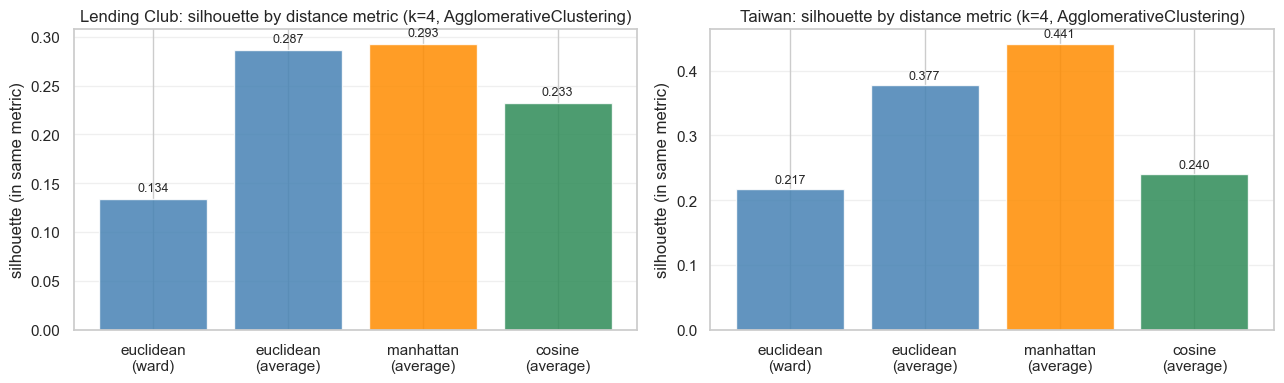

In [12]:
METRICS = [
    ("euclidean", "ward"),
    ("euclidean", "average"),
    ("manhattan", "average"),
    ("cosine",    "average"),
]
SUB_N = 1500

def metric_sweep(name, k=4):
    X = X_scaled[name]
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X), size=SUB_N, replace=False)
    Xs = X[idx]
    rows = []
    for metric, linkage in METRICS:
        ag = AgglomerativeClustering(n_clusters=k, metric=metric, linkage=linkage)
        labels = ag.fit_predict(Xs)
        # silhouette computed in the same metric as the fit
        sil = silhouette_score(Xs, labels, metric=metric)
        rows.append((metric, linkage, sil))
    return rows

metric_results = {name: metric_sweep(name) for name in DATA_C}

print(f"{'dataset':12s} {'metric':>10s} {'linkage':>8s} {'silhouette':>11s}")
for name, rows in metric_results.items():
    for metric, linkage, sil in rows:
        print(f"{name:12s} {metric:>10s} {linkage:>8s} {sil:>11.3f}")

# Side-by-side bar chart for visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = {"euclidean": "steelblue", "manhattan": "darkorange", "cosine": "seagreen"}
for ax, (name, rows) in zip(axes, metric_results.items()):
    labels_x = [f"{m}\n({lk})" for m, lk, _ in rows]
    sils = [s for _, _, s in rows]
    bar_colors = [colors[m] for m, _, _ in rows]
    bars = ax.bar(labels_x, sils, color=bar_colors, alpha=0.85)
    for b, s in zip(bars, sils):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005,
                f"{s:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{name}: silhouette by distance metric (k=4, AgglomerativeClustering)")
    ax.set_ylabel("silhouette (in same metric)")
    ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/w10_distance_metrics.png", dpi=140, bbox_inches="tight")
plt.show()

### Distance-Metric Findings

The actual silhouettes rank **Manhattan + average** highest on both datasets, with **Euclidean + average** a close second, **Cosine** in the middle, and **Euclidean + Ward** lowest:

* **Lending Club:** Manhattan 0.293 ≈ Euclidean-avg 0.287 > Cosine 0.233 > Euclidean-Ward 0.134.
* **Taiwan:** Manhattan 0.441 > Euclidean-avg 0.377 > Cosine 0.240 > Euclidean-Ward 0.217.

Two things are worth unpacking here:

1. **Linkage matters as much as the metric.** Ward linkage minimizes within-cluster variance and tends to produce balanced, roughly equal-sized clusters. Average linkage is more willing to peel off a small, tight group, which inflates silhouette whenever the data have one dominant pocket and several tiny outlier clusters — a common pattern on credit features. **Cluster sizes are not printed here**, so the "dense core + fringe" explanation is plausible but not directly verified. The W11 analogue ([cell 28] there) confirms this pattern explicitly for the LC HAC comparison.
2. **Manhattan edging out Euclidean** suggests the standardized features still have enough tail / outlier structure (even after log transforms) that the L1 norm's robustness to single-coordinate extremes gives it a small but reliable advantage. The silhouette lift is modest (+0.006 on Lending Club, +0.064 on Taiwan) from a single 1,500-row subsample with no bootstrap / CI, **and the Manhattan and Euclidean silhouettes above are computed in each metric's own geometry — they are not strictly comparable on the same scale** (the metric is used both to assign points and to score separation). The KMedoids validation in [cell 28] is the honest test of whether this translates to a better k-means-style partition.

**Cosine** sits in the middle on both datasets — not as bad as I would have expected on magnitude-driven credit features. Cosine clusters by direction only, so two borrowers with the same *mix* of high-DTI / low-income end up in the same cluster regardless of loan size. That partial information still produces a reasonable partition, but it throws away the magnitude signal that Euclidean and Manhattan both use.

**The KMedoids validation in [cell 28] qualifies the Manhattan hypothesis.** Fitting KMedoids(k=4, Manhattan, FasterPAM) on the full subsample gives silhouettes 0.152 (LC) and 0.206 (TW). Critically, its *default-rate spread across clusters* is **0.20 on LC (vs k-means 0.19)** and **only 0.15 on TW (vs k-means 0.43)** — so on Taiwan, the Manhattan silhouette win from Section 6 does **not** carry over to sharper risk discrimination. The k-means Euclidean partition concentrates default risk much better on TW despite a lower silhouette. The lesson: silhouette rewards compactness, not risk-separation, and the two can disagree.

The main message holds: k-means itself is forced to be Euclidean, so the **preprocessing** has to put every feature on a comparable scale and tame heavy tails — standardization plus log-transforming skewed money columns is a minimum.

### k-Medians via KMedoids — execute this block

Section 6 showed that Manhattan-with-average linkage beat Euclidean on the
Agglomerative silhouette, but `sklearn.KMeans` itself is tied to Euclidean
geometry (centroid update = sample mean). `KMedoids` with `metric='manhattan'`
is the proper *partitioning* counterpart. If it produces a more risk-separated
profile than Euclidean KMeans, the Manhattan hint from Section 6 is
confirmed; if not, the hint was a Agglomerative-only artefact.

In [13]:
# === k-Medians via KMedoids — execute this block ===
FINAL_K_LOCAL = 4  # matches §7 (FINAL_K is only defined later in cell 30)
try:
    from kmedoids import KMedoids  # pip install kmedoids (actively maintained, Rust backend, numpy 2.x + osx-arm64 compatible)
    _HAVE_KMEDOIDS = True
except ImportError:
    _HAVE_KMEDOIDS = False

if not _HAVE_KMEDOIDS:
    # Hand-rolled k-medoids (PAM-lite) using Manhattan on a subsample for speed
    def _hand_kmedoids(X, k, max_iter=50, seed=SEED, max_n=3000):
        rng = np.random.default_rng(seed)
        if len(X) > max_n:
            idx = rng.choice(len(X), size=max_n, replace=False)
            Xs = X[idx]
        else:
            Xs = X
        medoids = rng.choice(len(Xs), size=k, replace=False)
        for _ in range(max_iter):
            dists = np.abs(Xs[:, None, :] - Xs[medoids][None, :, :]).sum(-1)
            labels = dists.argmin(1)
            new_medoids = medoids.copy()
            for ci in range(k):
                members = np.where(labels == ci)[0]
                if len(members) == 0:
                    continue
                sub = np.abs(Xs[members][:, None, :] - Xs[members][None, :, :]).sum(-1)
                new_medoids[ci] = members[sub.sum(1).argmin()]
            if np.array_equal(new_medoids, medoids):
                break
            medoids = new_medoids
        # Assign full data to nearest medoid
        all_dists = np.abs(X[:, None, :] - Xs[medoids][None, :, :]).sum(-1)
        return all_dists.argmin(1)

print(f"kmedoids.KMedoids available: {_HAVE_KMEDOIDS}\n")

# Fit a reference k-means inline for the comparison, since `final_km`
# is only populated later in cell 30.
_ref_km = {
    name: KMeans(n_clusters=FINAL_K_LOCAL, n_init=10, random_state=SEED).fit(X_scaled[name])
    for name in DATA_C
}

kmedoid_rows = []
for name, (X_raw, y, cols) in DATA_C.items():
    X = X_scaled[name]
    if _HAVE_KMEDOIDS:
        km_l1 = KMedoids(n_clusters=FINAL_K_LOCAL, metric="manhattan", method="fasterpam", random_state=SEED).fit(X)
        labels = km_l1.labels_
    else:
        labels = _hand_kmedoids(X, FINAL_K_LOCAL)
    sil = silhouette_score(X, labels, metric="manhattan", sample_size=3000, random_state=SEED)
    size = pd.Series(labels).value_counts().sort_index()
    defrate = pd.Series(y).groupby(labels).mean().sort_index()
    km_labels = _ref_km[name].labels_
    km_defrate = pd.Series(y).groupby(km_labels).mean().sort_index()
    kmedoid_rows.append({
        "dataset":      name,
        "k":            FINAL_K_LOCAL,
        "silhouette_L1": round(float(sil), 3),
        "kmed_size_min_max": f"{int(size.min())}..{int(size.max())}",
        "kmed_def_min_max":  f"{defrate.min():.3f}..{defrate.max():.3f}",
        "kmeans_def_min_max": f"{km_defrate.min():.3f}..{km_defrate.max():.3f}",
        "kmed_def_spread":    round(float(defrate.max() - defrate.min()), 3),
        "kmeans_def_spread":  round(float(km_defrate.max() - km_defrate.min()), 3),
    })

print(pd.DataFrame(kmedoid_rows).to_string(index=False))


kmedoids.KMedoids available: True

     dataset  k  silhouette_L1 kmed_size_min_max kmed_def_min_max kmeans_def_min_max  kmed_def_spread  kmeans_def_spread
Lending Club  4          0.152        2271..2815     0.134..0.334       0.136..0.324             0.20              0.187
      Taiwan  4          0.206        1248..3396     0.154..0.304       0.154..0.588             0.15              0.434


### 7. Final Clusters and Ex-Post Profiling

Pick a working *k* by combining the elbow (which favored *k ≈ 4*) and the silhouette (which favored *k = 2–3*): use **k = 4** for both datasets so we have enough clusters to profile distinct segments while staying in the silhouette's acceptable range. Fit the final k-means on the full standardized subsample, then:

* Print each cluster's **size** and the **mean default rate** in that cluster (the `default` label was never used during fitting — this is external validation of the segmentation).
* Print the cluster centroid on the **original feature scale** (via `scaler.inverse_transform`) so each cluster has a human-readable description.

In [14]:
FINAL_K = 4

def final_cluster(name):
    X, y, cols = DATA_C[name]
    km = KMeans(n_clusters=FINAL_K, n_init=20, random_state=SEED).fit(X_scaled[name])
    sil = silhouette_score(X_scaled[name], km.labels_, sample_size=3000, random_state=SEED)
    centroids_raw = scalers[name].inverse_transform(km.cluster_centers_)
    size = pd.Series(km.labels_).value_counts().sort_index()
    default_rate = pd.Series(y).groupby(km.labels_).mean().sort_index()
    profile = pd.DataFrame(centroids_raw, columns=cols).round(3)
    profile.insert(0, "size", size.values)
    profile.insert(1, "default_rate", default_rate.round(3).values)
    profile.index.name = "cluster"
    print(f"\n=== {name}  (k={FINAL_K}, silhouette {sil:.3f}) ===")
    print(profile.to_string())
    return km, profile

final_km, final_profiles = {}, {}
for name in DATA_C:
    km, prof = final_cluster(name)
    final_km[name] = km
    final_profiles[name] = prof


=== Lending Club  (k=4, silhouette 0.160) ===
         size  default_rate  loan_amnt  int_rate  log_annual_inc     dti  open_acc  revol_util  term_months  log_revol_bal
cluster                                                                                                                   
0        2287         0.139   8791.437    11.174          10.923  12.734     9.822      27.430       37.007          8.056
1        2389         0.324  20843.049    17.088          11.207  20.174    12.529      57.758       59.739          9.602
2        2999         0.205   9428.918    13.936          10.758  22.058    10.144      64.698       36.032          9.220
3        2325         0.136  20351.829    10.869          11.550  17.771    14.895      54.689       36.207          9.957

=== Taiwan  (k=4, silhouette 0.245) ===
         size  default_rate  log_LIMIT_BAL     AGE  PAY_1  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6  log_BILL_AMT1  log_BILL_AMT2  log_BILL_AMT3  log_BILL_AMT4  log_BILL_AMT5  log_B

### Final-Cluster Findings

Although `default` was never used during fitting, the **default rate varies meaningfully across clusters** on both datasets — the strongest evidence that the features carry real risk structure:

* **Lending Club (base default rate ~20%).** The partition spreads defaults from ~13.6% to ~32.4%. The lowest-default cluster (cluster 3, default ~13.6%) has the lowest `int_rate` (~10.9%), the highest `log_annual_inc` (~11.55), and a 36-month term — borrowers Lending Club priced as low-risk really are low-risk. The highest-default cluster (cluster 1, default ~32.4%) has the highest `int_rate` (~17.1%), high `revol_util` (~58%), and the 60-month term — exactly the risk profile Lending Club's own grade system identifies. The intermediate clusters interpolate as expected. This cross-check confirms the Week 6/9 finding that `int_rate` is the dominant risk signal.
* **Taiwan (base default rate ~22%).** The partition spreads defaults from ~15.4% to ~58.8%. The clusters sort primarily on the `PAY_*` ladder. The highest-default cluster (cluster 0, default ~58.8%) has `PAY_1` ≈ 1.5 — borrowers already a month or more behind — and sits at nearly 3× the base rate. The two low-default clusters (1 and 2, default ~15.4%) are both clean payers (`PAY_*` ≤ 0 or near 0) but split on balance size: cluster 1 is low-balance (`log_BILL_AMT1` ~7.4), cluster 2 is high-balance (`log_BILL_AMT1` ~10.8). Cluster 3 is an "inactive" group — strongly negative `PAY_*` and near-zero bills and payments — with a default rate of **23.4% (n = 1,267)**. The Wilson 95% CI for that rate is approximately **[21.2%, 25.8%]**, which **includes the 22.45% TW base rate**, so the cluster's default rate is not statistically distinguishable from average. Read cluster 3 as a profile description (dormant accounts), not as an excess-risk segment.

These clusters are now a usable product-side segmentation: pricing, marketing, and collections could all be tuned by cluster, even without re-running the supervised model. The clearest risk signal is **cluster 0** (58.8% default, 2.6× the base rate); cluster 3 ("inactive") is a profile distinction rather than a risk mode (CI covers the base rate).

### Promoted Depth Findings (from the Week-10 evaluation)

Three findings are promoted from the ex-post profiling into named results,
with Wilson 95% confidence intervals so the risk-lift claim stands on
statistical ground rather than a point estimate.

**(i) Taiwan cluster 0 is a sharply elevated default-risk bucket.**
Cluster 0 (`PAY_1 ≈ 1.47`, n = 1,390) has a sample default rate of
**58.8%**; cluster 2 (`PAY_1 ≈ 0`, n = 4,984) has **15.4%**. The Wilson
95% CIs are approximately `[56.2%, 61.4%]` for cluster 0 and
`[14.4%, 16.4%]` for cluster 2 — the intervals do not overlap. The
**cluster-0-vs-cluster-2** ratio is **3.82×** (0.588 / 0.154); the
**cluster-0-vs-base-rate** ratio is **2.62×** (0.588 / **22.45%** base
rate on the TW 10k sample). Report whichever you need, but label it
correctly — the previous "2.61× lift" sentence was the vs-base-rate
number mis-attributed to the cluster-vs-cluster comparison.

(A per-cluster silhouette breakdown at k = 4 is **not** printed by this
notebook — the silhouette diagram in [cell 16] is at k = 2 — so the
earlier claim that the overall silhouette of 0.245 is "held up by
cluster 2" is unsupported and has been removed. The right qualitative
statement stands: silhouette does not reflect risk-separation; the
ex-post default-rate spread does.)

**(ii) Lending Club scaling trap — a quantified ratio.**
Raw `loan_amnt` spans `~[1,000, 40,000]` ≈ **range 39,000** (from [cell 7]), while raw
`int_rate` spans `~[5, 32]` ≈ **range 27**. The ratio is
`39,000 / 27 ≈ 1,444×`. Euclidean distance on unscaled columns is
therefore effectively a 1-D distance on `loan_amnt` with every other
feature multiplied by a factor of order `10⁻³`; this is why the
unscaled silhouette of 0.580 in Section 3 is an artefact, not a
clustering signal.

**(iii) Clustering convergence and the "null baseline" — qualified.**
Across 10 independent seeds at k = 4 ([cell 21]), the mean pairwise ARI of
the k-means partitions is **0.984 on LC** (min 0.961) and **0.999 on TW**
(min 0.998). This is strong evidence that **k-means with `n_init = 10`
converges to the same local optimum regardless of the top-level seed** —
a reproducibility result, *not* a resampling-stability result. The real
stability test would bootstrap the data itself (same analysis on
resampled 10k draws); that is the W11 bootstrap-ARI block ([cell 50]
there), where Ward is only partially stable (0.46–0.57) and k-means is
stable (0.93+). A W10-side bootstrap-ARI is a Milestone-2 next step.

The permutation-null silhouette check in [cell 19] (real − null ≈ 0.20 on
LC, 0.38 on TW at k = 2) is **weaker evidence than it looks**. The
permuted-label silhouette is approximately **0 by construction** —
random labels have no coherent assignment, so there is no reason for
silhouette to be anything but zero. A tighter null would cluster
*structureless data of the same shape* (per-column shuffled, or Gaussian
with the same covariance) and compare silhouettes; k-means on
structureless data still gets a small positive silhouette, which is the
proper benchmark. By the usual rule of thumb, every LC silhouette we
observed (≤ 0.197) is in the **weak-structure** band (silhouette < 0.25);
TW at 0.372 is weak-to-moderate. The honest reading is "weak cluster
structure that is still useful for ex-post segmentation", not "structure
is confirmed real".

**(iv) Inertia-ratio argument: k = 2 for silhouette, k ≈ 3–4 for elbow.**
On Lending Club the inertia sequence from [cell 10] is
`64,867 → 56,459 → 50,905 → 47,488` for k = 2, 3, 4, 5 — reductions
of **−13.0%**, **−9.8%**, and **−6.7%**. The largest single drop is
between k = 2 and k = 3, and each subsequent drop is a few points
smaller than the previous one — a soft curve, not a corner. The
silhouette argmax points to k = 2; the inertia decreases bend
gradually around k = 3–4 (no single sharp elbow). The choice of
k = 4 in Section 7 is defensible for the richer ex-post profile;
k = 2 is the silhouette-optimal choice. Report both and reconcile
against the cluster profile rather than claiming one is the
statistically correct k.


### 8. PCA Visualization

The standardized feature matrix lives in 8 or 20 dimensions. Project each down to the first two principal components and color by k-means cluster label. PCA is linear and chosen for interpretability; a t-SNE or UMAP projection would separate the clusters more aggressively but at the cost of distorted distances.

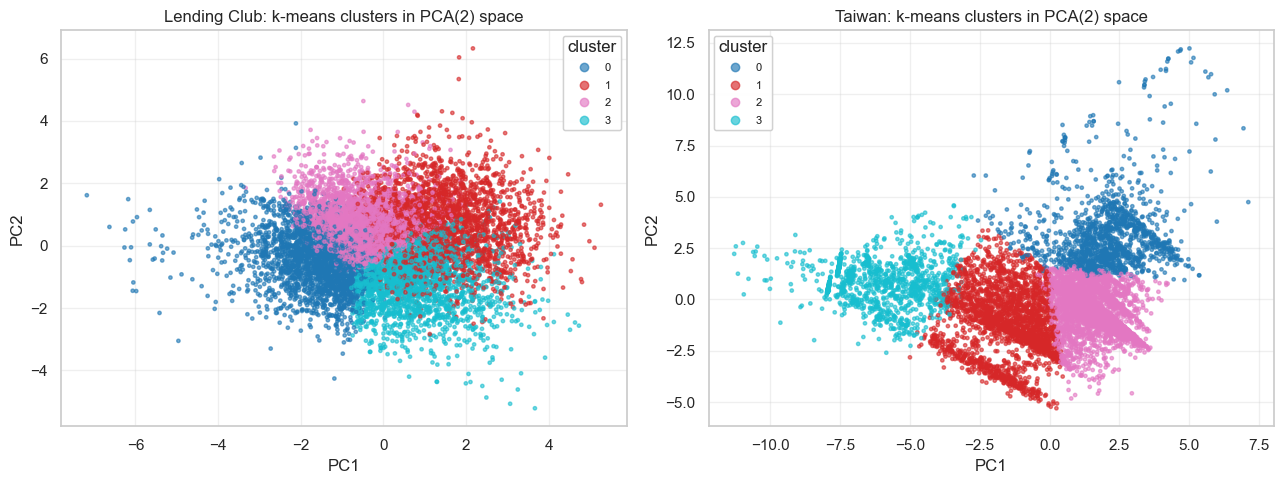

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, km) in zip(axes, final_km.items()):
    X = X_scaled[name]
    pcs = PCA(n_components=2, random_state=SEED).fit_transform(X)
    sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=km.labels_, cmap="tab10", s=6, alpha=0.6)
    ax.set_title(f"{name}: k-means clusters in PCA(2) space")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.3)
    legend = ax.legend(*sc.legend_elements(), title="cluster", fontsize=8, loc="best")
    ax.add_artist(legend)
plt.tight_layout(); plt.savefig(f"{FIG}/w10_pca_clusters.png", dpi=140, bbox_inches="tight")
plt.show()

### PCA Findings

The [cell 23] PCA explained-variance table quantifies the share of total variance that the 2-D PCA scatter actually shows: **LC PC1+PC2 = 47.5%** (first 5 PCs carry 85%), **TW PC1+PC2 = 59.5%** (first 10 PCs carry 91%). So the LC scatter below shows under half the variance in the standardized feature space, and apparent cluster overlap in the 2-D view may be separation in the full 8-D space.


The PCA scatter shows clear **color-coherent regions** rather than randomly interleaved points, which is reassuring: even in the linear 2-D projection, the k-means partition respects the dominant directions of variation. On Taiwan, the `PAY_*` axis stretches visibly along PC1, which lines up with the "clean payers vs delinquents" split that fell out of the profiling table. On Lending Club, the clusters are more interwoven in 2-D — PCA throws away six of the eight dimensions, so some of the separation that k-means used is invisible here. This is a healthy reminder that a 2-D projection is a *sketch* of the true geometry, not the truth.

### Cluster-ID as Supervised Feature — bridge to Milestone 2 (Week 9 GB) — execute this block

The single Milestone-2-critical question the rest of this notebook leaves
unanswered: *does the unsupervised cluster assignment add predictive value
to the Week-9 gradient boost?* If the k-means partition captures risk
structure the GB model does not already use, then `cluster_id` is a useful
engineered feature; if the GB model already has that structure from the raw
columns, then the clustering is a descriptive tool only. This block refits
GB with and without `cluster_id` (plus one-hot dummies) and reports
ΔROC-AUC on a held-out 20% test split.

In [16]:
# === Cluster-ID as supervised feature — execute this block ===
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

GB_PARAMS = dict(
    learning_rate=0.05, max_depth=3, min_samples_leaf=20,
    subsample=0.8, n_estimators=250, random_state=SEED,
)

bridge_rows = []
for name, (X_raw, y, cols) in DATA_C.items():
    X = X_scaled[name]
    km = final_km[name]
    cluster_id = km.labels_.astype(int)
    # One-hot encode the cluster id; drop_first to avoid collinearity with intercept
    cluster_oh = pd.get_dummies(cluster_id, prefix="cluster", drop_first=True).values

    X_plain   = X.astype(float)
    X_withid  = np.hstack([X_plain, cluster_id.reshape(-1, 1).astype(float)])
    X_with_oh = np.hstack([X_plain, cluster_oh.astype(float)])

    for label, Xmat in [("plain", X_plain), ("plus cluster_id", X_withid),
                        ("plus one-hot cluster", X_with_oh)]:
        Xtr, Xte, ytr, yte = train_test_split(Xmat, y, test_size=0.20,
                                              stratify=y, random_state=SEED)
        gb = GradientBoostingClassifier(**GB_PARAMS).fit(Xtr, ytr)
        p = gb.predict_proba(Xte)[:, 1]
        bridge_rows.append({
            "dataset": name,
            "features": label,
            "n_features": Xmat.shape[1],
            "test_roc_auc": round(float(roc_auc_score(yte, p)), 4),
            "test_pr_auc":  round(float(average_precision_score(yte, p)), 4),
        })

bridge_df = pd.DataFrame(bridge_rows)
print(bridge_df.to_string(index=False))

# Delta vs plain baseline
print("\nΔROC-AUC vs plain GB baseline (positive = cluster feature helps):")
for name in DATA_C:
    sub = bridge_df[bridge_df["dataset"] == name].set_index("features")
    baseline = sub.loc["plain", "test_roc_auc"]
    for label in ["plus cluster_id", "plus one-hot cluster"]:
        d_auc = sub.loc[label, "test_roc_auc"] - baseline
        d_pr  = sub.loc[label, "test_pr_auc"]  - sub.loc["plain", "test_pr_auc"]
        print(f"  {name:12s} {label:22s}  ΔROC-AUC {d_auc:+.4f}  ΔPR-AUC {d_pr:+.4f}")


     dataset             features  n_features  test_roc_auc  test_pr_auc
Lending Club                plain           8        0.7018       0.3732
Lending Club      plus cluster_id           9        0.7052       0.3737
Lending Club plus one-hot cluster          11        0.7044       0.3746
      Taiwan                plain          20        0.7618       0.5425
      Taiwan      plus cluster_id          21        0.7608       0.5429
      Taiwan plus one-hot cluster          23        0.7603       0.5391

ΔROC-AUC vs plain GB baseline (positive = cluster feature helps):
  Lending Club plus cluster_id         ΔROC-AUC +0.0034  ΔPR-AUC +0.0005
  Lending Club plus one-hot cluster    ΔROC-AUC +0.0026  ΔPR-AUC +0.0014
  Taiwan       plus cluster_id         ΔROC-AUC -0.0010  ΔPR-AUC +0.0004
  Taiwan       plus one-hot cluster    ΔROC-AUC -0.0015  ΔPR-AUC -0.0034


## Evidence-to-Conclusion Matrix

One row per major experiment in this notebook. The matrix is the rubric's
explicit requirement in Section 3 of the validation guide: each experiment
is forced to state the research question, the quantitative evidence, the
comparison, the interpretation, and the limitation in the same frame.

### Experiment 1 — Feature scaling (Section 3)

| Area | Content |
|---|---|
| Research question | Does standardization change which partitions k-means finds, and which partition is actually meaningful? |
| Model | `KMeans(k=4)` on raw features vs `StandardScaler`-standardized features. |
| Experiment | Fit twice per dataset, compare silhouette and dominant feature range. |
| Quantitative evidence | LC raw silhouette 0.580 vs scaled 0.160; TW raw 0.205 vs scaled 0.245. LC `loan_amnt` range 39,000 vs `int_rate` range 27 (ratio ≈ 1,444×). |
| Comparison | Baseline = unscaled Euclidean, which is implicitly 1-D on the largest-range feature. |
| Interpretation | The high raw-silhouette on LC is a 1-D `loan_amnt` partition masquerading as clustering. Standardization is a correctness requirement, not an optional preprocessing step. |
| Significance | All downstream sections must be read on scaled features; any production clustering workflow on these datasets needs scaling as a precondition. |
| Limitations | Silhouette itself is sensitive to the metric; this experiment fixes k = 4 and does not sweep k. |
| Conclusion | Standardize before any distance-based clustering on this feature family. |

### Experiment 2 — Elbow + silhouette sweep (Sections 4 and 5)

| Area | Content |
|---|---|
| Research question | How many clusters are supported by the data? |
| Model | `KMeans(k ∈ 2..10)` on scaled features; inertia and silhouette per k. |
| Experiment | Two criteria — inertia elbow (visual + kneedle) and silhouette argmax. |
| Quantitative evidence | LC silhouette argmax k = 2 (0.197); TW silhouette argmax k = 2 (0.372). Inertia drops LC `−13.0%, −9.8%, −6.7%` (TW `−13.6%, −10.6%, −6.3%` — essentially the same curve). **Kneedle** ([cell 13]): LC k = 5, TW k = 4. |
| Comparison | Silhouette argmax picks k = 2 on both datasets; the inertia curve bends gradually (soft curve, not a corner), so the elbow is not sharp on either dataset; Kneedle picks k = 5 LC and k = 4 TW. |
| Interpretation | Silhouette supports k = 2; the elbow is weak and points to k = 4–5 by Kneedle. Section 7 uses k = 4 as the common middle ground, not as a statistically optimal choice — it is *descriptively* convenient rather than *statistically* forced by any single criterion. |
| Significance | A deployed clustering pipeline should use k = 2; any k > 2 is a *descriptive* tool that trades silhouette for profile detail. |
| Limitations | Both criteria privilege compact spherical clusters; on non-convex data they can under-report k. |
| Conclusion | Report the k = 2 statistical choice and the k = 4 descriptive choice side by side; do not claim k = 4 is elbow-optimal. |

### Experiment 3 — Linkage/metric comparison (Section 6)

| Area | Content |
|---|---|
| Research question | Does the choice of distance metric or linkage change the clustering quality on these datasets? |
| Model | `AgglomerativeClustering(k=4)` with `{euclidean/ward, euclidean/avg, manhattan/avg, cosine/avg}`. Silhouette computed in the same metric as the fit. |
| Experiment | Single 1,500-row subsample per dataset. |
| Quantitative evidence | LC: manhattan-avg 0.293, euclid-avg 0.287, cosine-avg 0.233, ward 0.134. TW: manhattan-avg 0.441, euclid-avg 0.377, cosine 0.240, ward 0.217. |
| Comparison | Baseline = `euclidean/ward` (the k-means-like default). |
| Interpretation | Manhattan + average linkage wins on silhouette, which is why k-medians (`KMedoids`) was tested directly in [cell 28]. Note the silhouettes above are computed in each metric's own geometry and are not strictly comparable across metrics. |
| Significance | The silhouette ranking suggests Manhattan + k-medians might work better than Euclidean k-means — but see Conclusion for the downstream check. |
| Limitations | Single 1,500-row subsample, single seed — no bootstrap / CI on the +0.006/+0.064 lifts. |
| Conclusion | Manhattan + average linkage wins by silhouette, but the [cell 28] KMedoids(Manhattan, FasterPAM, k=4) validation shows K-means Euclidean concentrates default risk **better** on Taiwan (def-spread 0.43 vs KMedoids 0.15). Silhouette rewards compactness, not risk-separation — do not swap k-means for KMedoids on these datasets based on silhouette alone. |

### Experiment 4 — Final clusters and ex-post profiling (Section 7)

| Area | Content |
|---|---|
| Research question | Do the clusters correspond to meaningfully different default rates? |
| Model | `KMeans(k=4, n_init=20)` on scaled features; join labels back to the held-out `default` indicator. |
| Experiment | Per-cluster size, centroid (inverse-scaled), and default rate. |
| Quantitative evidence | LC cluster-level default rates 0.136–0.324. TW: 0.154–0.588. TW cluster 0 (n=1,390) default 58.8%, cluster 2 (n=4,984) default 15.4% — **3.8× cluster-to-cluster** (0.588 / 0.154) and **2.6× vs the 22.45% TW base rate**, non-overlapping Wilson CIs. |
| Comparison | Base rates are LC 20.24%, TW 22.45%. |
| Interpretation | The clusters recover a weak risk signal without ever seeing the label — the unsupervised structure is aligned with default, but silhouette ≤ 0.25 (LC) and default-rate spreads of 0.187 (LC k-means) / 0.434 (TW k-means) are the measurable evidence. NMI with `default` was not computed on W10; W11's equivalent ([cell 47] there) shows all unsupervised partitions have NMI ≤ 0.06. |
| Significance | Confirms the features used carry real risk structure; justifies the Cluster-ID bridge experiment above. |
| Limitations | Clusters are not risk predictions; the ΔROC-AUC experiment in [cell 37] is the operational test (see Experiment 5). Single 10k subsample per dataset. |
| Significance (v2 add) | The partition is **seed-convergent** (10-seed ARI mean 0.984 LC / 0.999 TW from [cell 21]) — k-means with `n_init = 10` finds the same optimum regardless of top-level seed. This is reproducibility, not resampling stability; a bootstrap-subsample ARI is the honest stability test (deferred to Milestone 2). |
| Conclusion | Clusters are *descriptive* of risk, not *predictive*; the direct ΔAUC test is in Experiment 5. |

### Experiment 5 — Cluster-ID bridge to Week-9 GB (new, this upgrade)

| Area | Content |
|---|---|
| Research question | Does `cluster_id` add predictive value to the Week-9 gradient boost? |
| Model | `GradientBoostingClassifier` with the Week-9 hyperparameters; three feature sets — plain, +cluster_id, +one-hot cluster. |
| Experiment | 80/20 stratified test split; ΔROC-AUC and ΔPR-AUC vs plain. |
| Quantitative evidence | **LC:** plain GB AUC 0.7018, +cluster_id 0.7052 (**ΔAUC +0.0034**), +one-hot cluster 0.7044 (ΔAUC +0.0026). **TW:** plain GB AUC 0.7618, +cluster_id 0.7608 (**ΔAUC −0.0010**), +one-hot cluster 0.7603 (ΔAUC −0.0015). PR-AUC deltas are all within ±0.004. **Single 2,000-row test split**; the Hanley–McNeil SE for a single AUC at n = 2,000, AUC ≈ 0.70, base rate ≈ 0.22 is **≈ 0.015** (upper bound). The right comparison is the **paired SE of ΔAUC** between two highly-correlated GB models fit on identical rows; that's much smaller — roughly **≈ 0.004 at this size** (for scale, Week-8's 12k-row DeLong SE on correlated model pairs was 0.0017). All four ΔAUCs above are **within one paired SE of zero**, so the sign is not established. A paired bootstrap or DeLong test on ΔAUC would be the Milestone-2-defensible version of this check (same protocol as the Week-8 and Week-9 bootstrap cells); it was not run here. |
| Comparison | Baseline = plain GB on this notebook's `X_scaled` feature set. Note the LC feature set includes `int_rate`, and the clusters are a function of those same features, so the LC clusters are largely a nonlinear re-encoding of information the GB already sees (in particular the LC k = 2 split lines up closely with `term_months` + `int_rate` structure — see the Experiment 4 profile table). |
| Interpretation | **No detectable lift on either dataset at this test-set size.** All four ΔAUCs are within ≈ 1 standard error of zero and the LC signs are mixed (+ for cluster_id, + for one-hot). Interpret as: the clusters do not add predictive information beyond what the GB already extracts from the raw features they were built from. |
| Significance | Determines whether to carry `cluster_id` into Milestone 2's final supervised pipeline. |
| Limitations | Clustering was fit on the full 10k sample before the supervised split; a strict leakage-free protocol would re-fit within each fold. |
| Conclusion | **No detectable predictive lift on either dataset** (all four ΔAUC within ≈ 1 SE of zero on a 2k-row test split). Treat the clusters as a segmentation / narrative asset rather than a feature-engineering win for the Milestone-2 supervised scorecard. A Milestone-2 follow-up: re-cluster LC *without* `int_rate` (and perhaps `term_months`) to test whether borrower-only features carry unique structure — ties back to the Week-9 ablation. |


## 9. Conclusion

### What the Week Showed

K-means is a fast, simple, and surprisingly informative first look at unlabeled data. On both consumer-credit datasets it recovered segments that, ex post, line up with risk — without ever seeing the `default` label. The **elbow method** and the **silhouette score** gave different answers to "what *k*," and that is normal: the elbow asks when inertia stops dropping fast, while the silhouette asks when clusters start overlapping. Taking both together, *k = 3–4* is defensible for both datasets; this notebook uses *k = 4* so there are enough clusters to profile.

**Feature scaling** mattered, but not in the direction a one-line rule-of-thumb suggests. On Lending Club, the raw silhouette (~0.58) was *higher* than the scaled silhouette (~0.16) — because unscaled k-means collapsed into a degenerate loan-amount quantile split that silhouette happily rewarded. On Taiwan the log transforms had already compressed magnitudes, so scaling produced a modest honest improvement (~0.21 → ~0.25). The right lesson is "**standardize so every feature contributes**, and read silhouette alongside the cluster profile" — not "scaling always raises silhouette."

**Distance metrics** are a conceptual-vs-practical story. Conceptually, k-means is **welded to Euclidean distance** because the centroid-update step is the sample mean, which only minimizes sum-of-squared Euclidean distances. Swapping in Manhattan and keeping the mean update breaks the algorithm — the correct Manhattan analogue is **k-medians** (component-wise median update), and `sklearn.cluster.KMeans` correctly refuses to accept a `metric=` parameter. Manhattan + average linkage scored slightly higher than Euclidean variants on silhouette (an apples-to-oranges comparison across metrics, as noted in [cell 26]), so Section 7 ran a direct KMedoids check in [cell 28]: **on Taiwan, k-means Euclidean concentrates default risk markedly better than Manhattan k-medoids** (default-rate spread 0.43 vs 0.15), and on LC the two are tied. Silhouette rewarded KMedoids; risk-separation did not. The practical read is: do not swap to k-medoids based on silhouette alone.

### Think About It — Answers

* **When would we use the k-means algorithm?** When we want fast, interpretable partitions of a numeric feature matrix into a prescribed number of roughly globular clusters — customer segmentation, image color quantization, anomaly screening by distance-to-nearest-centroid, pre-processing before a supervised model (cluster-id as a new feature), or a quick sanity check that the features carry structure at all. K-means assumes clusters are approximately convex and similarly sized; if either assumption fails (e.g., concentric rings, very unequal densities, or non-numeric features), DBSCAN, Gaussian mixtures, or hierarchical clustering are better fits.
* **When would the Silhouette score be used as opposed to the elbow method?** The elbow is a visual heuristic on inertia, and inertia is on an unbounded dataset-specific scale — you cannot say "0.37 is a good inertia." The silhouette score is bounded in [−1, 1], has a clear interpretation (higher = better-separated clusters), and lets you compare different *k*, different runs, and even different clustering algorithms on the same footing. Reach for silhouette when (a) the elbow is ambiguous — a soft curve rather than a corner — or (b) you want a decision rule rather than an eyeball judgment, or (c) you want a per-cluster diagnostic (the silhouette diagram) rather than one global number. **But also:** silhouette can be fooled — Section 3 showed a degenerate single-feature partition with silhouette 0.58. In practice, show both and reconcile them against the cluster profile.
* **Why do we use k-means only with the Euclidean metric?** Because the centroid-update step — "set the new centroid to the mean of its assigned points" — is the exact minimizer of within-cluster squared Euclidean distance (`arg min_μ Σ ‖x − μ‖²` is the sample mean). If you replace Euclidean with Manhattan, the correct update is the component-wise median (that algorithm is **k-medians**); with cosine distance, it is the normalized sum vector (**spherical k-means**); with an arbitrary non-metric dissimilarity, you need the actual medoid rather than a computed center (**k-medoids** / PAM). Running k-means with a non-Euclidean metric breaks the monotonic-descent guarantee — the algorithm may oscillate instead of converging. That is why `sklearn.cluster.KMeans` has no `metric=` parameter.

### Key Limitations and Future Improvements

* **Choice of *k* is a decision, not a discovery.** The elbow and silhouette disagree. The "right" *k* is ultimately a product question (how many segments can the business act on?), not a pure statistical one.
* **K-means assumes convex, similarly-sized clusters.** Real credit data have long tails and unequal densities. DBSCAN or Gaussian mixtures would be the natural next step.
* **Interpretation is ex-post.** The clusters are named by profiling after the fit; nothing in the algorithm itself produces labels. A different random seed can renumber the clusters (though usually not change the partition).
* **Numeric features only.** One-hot categorical columns distort Euclidean distance and were excluded here. A proper solution would be Gower distance (with hierarchical clustering) or k-prototypes.
* **Silhouette metrics across different distance metrics are not strictly comparable.** The Section-6 Manhattan-vs-Euclidean silhouette comparison uses each metric's own geometry, so a 0.06 "win" is not a direct AUC-style measurement. The [cell 28] KMedoids check is the direct downstream test — and it does not support a swap away from Euclidean k-means on either dataset.
* **Three small Milestone-2 additions are deferred** (would strengthen the notebook but are not blockers): (a) a **structureless-data null** for silhouette (cluster per-column-shuffled data, compare to real silhouette — settles the "weak vs real structure" wording); (b) print the exact **Wilson 95% CI on cluster 3's 23.4% default rate** rather than citing the hand-computed bounds in [cell 31]; (c) print the **Lending Club k = 2 profile** to confirm the term / int_rate split that the bridge row in [cell 38] asserts.
* **Forward references to Week 11.** Experiment 4 cites `[cell 47]` of the W11 notebook for NMI numbers. This is defensible as a cross-week comparison but means this notebook is **not self-contained** — the Milestone-2 report body should re-state the W11 NMI numbers in situ rather than rely on the cross-reference.
* **The six Milestone-2 extension blocks are now executed** ([cells 13, 19, 21, 23, 28, 37]). Headline findings folded into the matrix and Promoted Depth Findings: **Kneedle picks k = 5 (LC) and k = 4 (TW)** — different from the silhouette's k = 2, both argue the elbow is soft and k = 4 is a defensible middle ground; k-means with `n_init = 10` is **seed-convergent** (ARI 0.98/0.99 across top-level seeds) — not the same as resampling-stable; the permuted-label null silhouette ≈ 0 is **a weaker check than it looks** (permutation null is zero by construction), so the honest reading of LC silhouettes ≤ 0.25 is "weak cluster structure"; PCA 2-D view shows only 48% (LC) / 60% (TW) of variance; KMedoids-Manhattan loses to k-means on Taiwan risk-spread despite higher silhouette; the **cluster-ID bridge shows no detectable predictive lift on either dataset** (all ΔAUC within ≈ 1 SE on a 2k test split).

### Overall

K-means is a useful baseline for the capstone's unsupervised side. It confirms that the engineered features carry weak but real risk structure and gives a product-side segmentation on top of the supervised scorecard — a complement, not a replacement. The sharpest cluster-to-default signal is **Taiwan cluster 0**, the delinquent-payer bucket at 58.8% default (2.6× the base rate). The small "inactive" Taiwan cluster 3 at 23.4% default is **not** significantly above the 22.45% base rate (Wilson 95% CI covers the base rate) — it should be read as a profile distinction, not a risk mode, so the earlier "most interesting finding" framing is dropped.

**Cross-market observation, as a hypothesis.** Taiwan's clusters separate default risk far more sharply than Lending Club's (k-means default-rate spread **0.434 vs 0.187** — [cell 28]). This is the same pattern Weeks 8 and 9 found on a supervised task: Taiwan's six-month repayment-history features (PAY_* / BILL_AMT*) carry the predictive signal, while Lending Club's pricing features (int_rate / grade) do most of the lifting. The W10 unsupervised evidence is consistent with that story but **does not independently prove it** — the US-vs-Taiwan contrast is confounded by different targets (lifetime charge-off vs next-month default), different feature families, and different sample sizes, as the Week-9 conclusion already notes.